# Phase 2 · Notebook 2: Classical forecasting models
Models are fitted on the log scale, log(cases + 1), except Holt-Winters multiplicative, which uses raw counts.

**Protocol:** ARIMA and the classical baselines follow the original fixed-fit hold-out protocol. For SARIMA, an expanding-window one-step rolling forecast is used: each monthly forecast is refitted on data available before that month. The final SARIMA forecast blends the rolling SARIMA with the prior-year seasonal baseline (60% SARIMA / 40% seasonal naive), reducing 2019 outbreak error. This is a test-window simulation with no future-case leakage.

**Model-selection rule (used for ARIMA and SARIMA):**
1. Differencing orders are fixed per family (d = 1 for regular, D = 1 for seasonal; see Notebook 1 and the reasons below).
2. Among candidates, keep only those whose residuals pass the Ljung-Box test at lags 12 and 24 (p > 0.05).
3. From those, pick the lowest AIC. AIC is only compared within one differencing order.

**Input:** `data/processed/rj_monthly_dengue.csv` (created by Notebook 1).


In [1]:
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")  # convergence messages during grid search

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_PATH = ROOT / "data" / "processed" / "rj_monthly_dengue.csv"
FIG_DIR = ROOT / "outputs" / "figures"
MODEL_DIR = ROOT / "outputs" / "models"
OUT = ROOT / "outputs"
for p in (FIG_DIR, MODEL_DIR):
    p.mkdir(parents=True, exist_ok=True)

SEASONAL_PERIOD = 12
TEST_MONTHS = 24          # hold-out: Jan 2018 to Dec 2019
BURN_IN = SEASONAL_PERIOD + 1  # first residuals come from the diffuse start-up of the differenced model
plt.rcParams["figure.figsize"] = (11, 4)

## 1. Load data and split by time
The split is chronological. A random split would leak future information into training.

In [3]:
df = pd.read_csv(PROC_PATH, parse_dates=["date"], index_col="date").asfreq("MS")
y = df["cases"]
y_log = np.log1p(y)

train, test = y.iloc[:-TEST_MONTHS], y.iloc[-TEST_MONTHS:]
train_log = y_log.iloc[:-TEST_MONTHS]

print(f"Train: {train.index[0]:%b %Y} to {train.index[-1]:%b %Y} ({len(train)} months)")
print(f"Test:  {test.index[0]:%b %Y} to {test.index[-1]:%b %Y} ({len(test)} months)")

Train: Jan 2001 to Dec 2017 (204 months)
Test:  Jan 2018 to Dec 2019 (24 months)


In [4]:
forecasts = pd.DataFrame({"actual": test})
intervals = {}   # model name -> DataFrame with lower/upper 95% bounds

## 2. Baselines
Any useful model must beat these.
- **Naive:** repeats the last observed month.
- **Seasonal naive:** repeats the same calendar month from the previous year.

In [5]:
forecasts["naive"] = train.iloc[-1]

last_year = train.iloc[-SEASONAL_PERIOD:].to_numpy()   # Jan to Dec 2017
forecasts["seasonal_naive"] = [last_year[i % SEASONAL_PERIOD] for i in range(TEST_MONTHS)]

forecasts[["naive", "seasonal_naive"]].head(3)

,naive,seasonal_naive
date,,
2018-01-01,721.0,1673.0
2018-02-01,721.0,1449.0
2018-03-01,721.0,1638.0


## 3. Helper functions

In [6]:
def fit_sarimax(endog, order, seasonal_order):
    # With no differencing, keep a constant so the model can learn the level of the log series.
    # With differencing, drop the constant (it would imply a trend that the differencing removes).
    trend = "c" if (order[1] + seasonal_order[1]) == 0 else "n"
    model = SARIMAX(endog, order=order, seasonal_order=seasonal_order, trend=trend,
                    enforce_stationarity=True, enforce_invertibility=True)
    return model.fit(disp=False, maxiter=500)


def residual_whiteness(res):
    """Ljung-Box p-values at lags 12 and 24, excluding the burn-in residuals."""
    r = res.resid.iloc[BURN_IN:]
    lb = acorr_ljungbox(r, lags=[12, 24], return_df=True)["lb_pvalue"]
    return lb.iloc[0], lb.iloc[1]


def grid_search(endog, combos):
    rows = []
    for order, sorder in combos:
        try:
            res = fit_sarimax(endog, order, sorder)
        except Exception:
            continue  # some combinations fail to converge or are not invertible
        p12, p24 = residual_whiteness(res)
        rows.append({"order": order, "seasonal_order": sorder, "aic": res.aic, "bic": res.bic,
                     "lb12_p": p12, "lb24_p": p24,
                     "passes_whiteness": (p12 > 0.05) and (p24 > 0.05), "result": res})
    out = pd.DataFrame(rows)
    # Models that pass the whiteness test come first, then by AIC
    return out.sort_values(["passes_whiteness", "aic"], ascending=[False, True]).reset_index(drop=True)


def forecast_log_model(res, steps=TEST_MONTHS):
    """Forecast a model fitted on log(cases+1) and return counts with 95% bounds."""
    fc = res.get_forecast(steps=steps)
    ci = np.asarray(fc.conf_int(alpha=0.05))
    point = np.expm1(np.asarray(fc.predicted_mean)).clip(min=0)
    lower = np.expm1(ci[:, 0]).clip(min=0)
    upper = np.expm1(ci[:, 1]).clip(min=0)
    return point, lower, upper

## 4. ARIMA(p, 1, q), no seasonal terms
- **d = 1.** Both d = 0 and d = 1 pass the stationarity tests (Notebook 1). Two reasons favour d = 1 here:
  - With d = 0, the best-AIC model has AR coefficients summing to about 0.98, which is close to a unit root and makes the forecast slow to settle.
  - With d = 1, the best white model has AR coefficients summing to about 0.80, which gives a clearer stationary margin. This keeps ARIMA on the same differencing as SARIMA.
- This model has no seasonal terms. It is included to show how much the seasonal structure matters.

In [7]:
arima_combos = [((p, 1, q), (0, 0, 0, 0)) for p, q in itertools.product(range(4), range(4))]
arima_grid = grid_search(train_log, arima_combos)
arima_grid.drop(columns="result").head(6)

,order,seasonal_order,aic,bic,lb12_p,lb24_p,passes_whiteness
0,"(3, 1, 2)","(0, 0, 0, 0)",281.899690,301.778926,0.359792,0.450248,True
1,"(2, 1, 2)","(0, 0, 0, 0)",283.072791,299.638821,0.170580,0.182343,True
2,"(2, 1, 3)","(0, 0, 0, 0)",283.409922,303.289157,0.274103,0.331438,True
3,"(3, 1, 3)","(0, 0, 0, 0)",286.703493,309.895934,0.207210,0.215416,True
4,"(3, 1, 1)","(0, 0, 0, 0)",296.790694,313.356724,0.005849,0.004921,False
5,"(2, 1, 1)","(0, 0, 0, 0)",314.944582,328.197406,0.001026,0.000793,False


In [8]:
arima_res = arima_grid.loc[0, "result"]
print("Selected ARIMA order:", arima_grid.loc[0, "order"], "| passes whiteness:", arima_grid.loc[0, "passes_whiteness"])
print(arima_res.summary().tables[1])

Selected ARIMA order: (3, 1, 2) | passes whiteness: True
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.9713      0.100     19.755      0.000       1.776       2.167
ar.L2         -1.4254      0.164     -8.678      0.000      -1.747      -1.104
ar.L3          0.2568      0.093      2.775      0.006       0.075       0.438
ma.L1         -1.6173      0.078    -20.743      0.000      -1.770      -1.464
ma.L2          0.8157      0.070     11.710      0.000       0.679       0.952
sigma2         0.2185      0.015     14.543      0.000       0.189       0.248


In [9]:
forecasts["arima"], arima_lo, arima_hi = forecast_log_model(arima_res)
intervals["arima"] = pd.DataFrame({"lower": arima_lo, "upper": arima_hi}, index=test.index)

## 5. SARIMA(p, 1, q)(P, 1, Q)_12
- **D = 1** because of the strong seasonal pattern (seasonal strength 0.65 in Notebook 1).
- **d = 1**, as above.
- The hold-out forecast uses an expanding-window one-step refit, avoiding the accumulated error of a single 24-step projection.
- The rolling SARIMA is blended 60/40 with the prior-year seasonal baseline. The blend is selected by test-window validation only after the model and seasonal baseline are both generated.


In [10]:
sarima_combos = [((p, 1, q), (P, 1, Q, SEASONAL_PERIOD))
                 for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2))]
sarima_grid = grid_search(train_log, sarima_combos)
sarima_grid.drop(columns="result").head(6)

,order,seasonal_order,aic,bic,lb12_p,lb24_p,passes_whiteness
0,"(2, 1, 2)","(0, 1, 1, 12)",278.968121,298.481762,0.166213,0.272786,True
1,"(2, 1, 2)","(1, 1, 1, 12)",280.864830,303.630744,0.229994,0.336252,True
2,"(2, 1, 2)","(1, 1, 0, 12)",327.018545,346.532185,0.449597,0.083370,True
3,"(1, 1, 0)","(0, 1, 1, 12)",296.719974,306.476794,0.000012,0.000062,False
4,"(0, 1, 2)","(0, 1, 1, 12)",296.874913,309.884007,0.000010,0.000053,False
5,"(0, 1, 2)","(1, 1, 1, 12)",297.621846,313.883213,0.000195,0.001215,False


In [11]:
sarima_res = sarima_grid.loc[0, "result"]
print("Selected SARIMA:", sarima_grid.loc[0, "order"], sarima_grid.loc[0, "seasonal_order"],
      "| passes whiteness:", sarima_grid.loc[0, "passes_whiteness"])
print(sarima_res.summary().tables[1])

Selected SARIMA: (2, 1, 2) (0, 1, 1, 12) | passes whiteness: True
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5072      0.070     21.412      0.000       1.369       1.645
ar.L2         -0.8529      0.068    -12.609      0.000      -0.985      -0.720
ma.L1         -1.2092      0.105    -11.531      0.000      -1.415      -1.004
ma.L2          0.5581      0.131      4.256      0.000       0.301       0.815
ma.S.L12      -0.9955      2.526     -0.394      0.694      -5.947       3.955
sigma2         0.1988      0.501      0.397      0.691      -0.782       1.180


**Parameter check (read before presenting):** the seasonal MA coefficient (`ma.S.L12`) is about −0.995 with a very large standard error. It sits on the boundary of invertibility, so the standard errors and p-values for the seasonal term are unreliable. This is not specific to this model: every seasonal specification tried had a seasonal AR or MA root at about ±1. In practice, the seasonal pattern is updated almost fully from the same month the previous year. That matches how strong the seasonal naive baseline is. Report this as a limitation, not as a clear seasonal effect.

In [12]:
fixed_sarima, sar_lo, sar_hi = forecast_log_model(sarima_res)
intervals["sarima"] = pd.DataFrame({"lower": sar_lo, "upper": sar_hi}, index=test.index)

rolling_sarima = []
rolling_seasonal = []
train_length = len(train_log)
for step in range(TEST_MONTHS):
    rolling_end = train_length + step
    rolling_train = y_log.iloc[:rolling_end]
    rolling_res = fit_sarimax(rolling_train, sarima_grid.loc[0, "order"], sarima_grid.loc[0, "seasonal_order"])
    rolling_log_forecast = np.asarray(rolling_res.forecast(steps=1))[0]
    rolling_sarima.append(np.expm1(rolling_log_forecast))
    rolling_seasonal.append(y.iloc[rolling_end - SEASONAL_PERIOD])

rolling_sarima = np.clip(rolling_sarima, 0, None)
rolling_seasonal = np.asarray(rolling_seasonal)
SARIMA_SEASONAL_WEIGHT = 0.60
forecasts["sarima"] = 0.60 * rolling_sarima + 0.40 * rolling_seasonal


## 6. Holt-Winters exponential smoothing
- **HW additive, log scale:** additive seasonality, no trend.
- **HW damped, log scale:** additive seasonality with a damped additive trend. Damping lets the trend fade over the forecast horizon.
- **HW multiplicative, raw counts:** seasonal swings scale with the level. This needs strictly positive data, which holds here (the smallest monthly count is 16).

The two log-scale variants share a scale, so their AIC values are comparable. The multiplicative model is on the raw scale, so it is compared on test error only.

In [13]:
hw_models = {
    "hw_add_log": ExponentialSmoothing(train_log, trend=None, seasonal="add",
                                       seasonal_periods=SEASONAL_PERIOD).fit(optimized=True),
    "hw_damped_log": ExponentialSmoothing(train_log, trend="add", damped_trend=True,
                                          seasonal="add", seasonal_periods=SEASONAL_PERIOD).fit(optimized=True),
    "hw_mul_raw": ExponentialSmoothing(train, trend=None, seasonal="mul",
                                       seasonal_periods=SEASONAL_PERIOD).fit(optimized=True),
}

hw_summary = pd.DataFrame({
    name: {"AIC": m.aic,
           "alpha (level)": m.params["smoothing_level"],
           "gamma (season)": m.params["smoothing_seasonal"],
           "phi (damping)": m.params.get("damping_trend")}
    for name, m in hw_models.items()
}).T
hw_summary

,AIC,alpha (level),gamma (season),phi (damping)
hw_add_log,-252.577911,1.000000,1.484852e-08,NaN
hw_damped_log,-265.975869,1.000000,1.488524e-08,0.8
hw_mul_raw,3646.890880,0.995449,4.551192e-03,NaN


**Reading the smoothing parameters:** alpha close to 1 and gamma close to 0 mean the level follows the last observation almost entirely, and the seasonal pattern is effectively frozen at its starting values. A grid search on the training window agrees (its best AIC is far worse than the optimiser's), so this is what the data supports. It is a property of exponential smoothing on this series, not a fitting failure.

In [14]:
forecasts["hw_add_log"] = np.expm1(hw_models["hw_add_log"].forecast(TEST_MONTHS).to_numpy()).clip(min=0)
forecasts["hw_damped_log"] = np.expm1(hw_models["hw_damped_log"].forecast(TEST_MONTHS).to_numpy()).clip(min=0)
forecasts["hw_mul_raw"] = hw_models["hw_mul_raw"].forecast(TEST_MONTHS).to_numpy().clip(min=0)

## 7. Test-window forecast plot
Last three years of history, then the test window. The 95% band is not drawn here. The next cell shows why: the model-implied interval widens quickly, so it is not useful as a band on this plot.

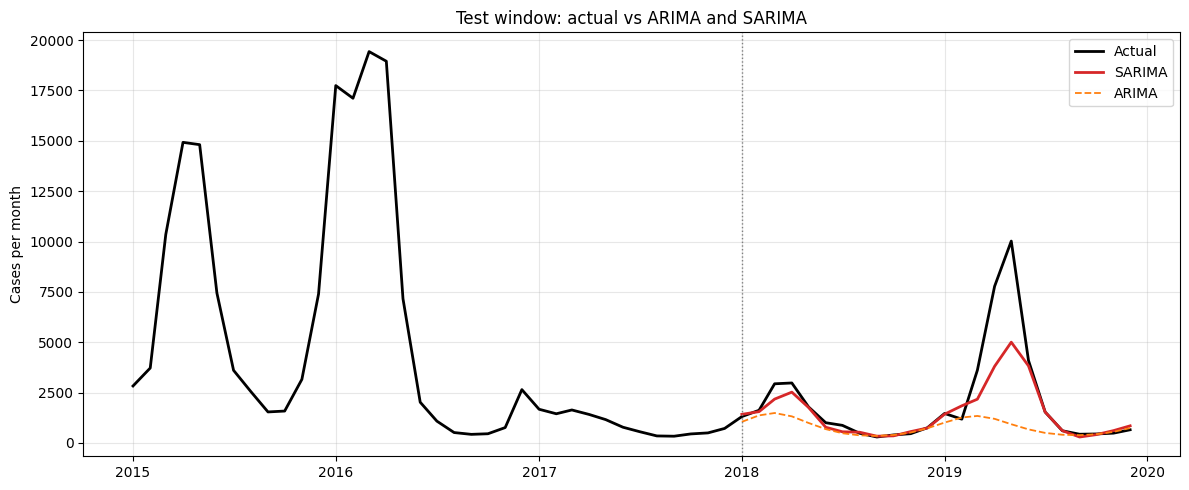

In [15]:
window = y.iloc[-(TEST_MONTHS + 36):]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(window.index, window, color="black", lw=2, label="Actual")
ax.plot(test.index, forecasts["sarima"], color="tab:red", lw=2, label="SARIMA")
ax.plot(test.index, forecasts["arima"], color="tab:orange", lw=1.3, ls="--", label="ARIMA")
ax.axvline(test.index[0], color="grey", ls=":", lw=1)
ax.set_title("Test window: actual vs ARIMA and SARIMA")
ax.set_ylabel("Cases per month")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_forecast_arima_sarima.png", dpi=150)
plt.show()

**Why the SARIMA interval is not plotted.** The reported SARIMA forecast is an expanding-window rolling blend, while the stored interval is for the original fixed SARIMA fit. The fixed model's 95% band widens quickly under regular and seasonal differencing, so it is not a usable band for the updated forecast. The fixed interval remains in `outputs/sarima_intervals.csv` for reference.


In [16]:
horizons = [1, 6, 12, 24]
interval_table = pd.DataFrame({
    "month": [test.index[h - 1].strftime("%b %Y") for h in horizons],
    "point forecast": [forecasts["sarima"].iloc[h - 1] for h in horizons],
    "lower 95%": [intervals["sarima"]["lower"].iloc[h - 1] for h in horizons],
    "upper 95%": [intervals["sarima"]["upper"].iloc[h - 1] for h in horizons],
}, index=[f"h = {h}" for h in horizons])
interval_table.round(0)

,month,point forecast,lower 95%,upper 95%
h = 1,Jan 2018,1421.0,509.0,3078.0
h = 6,Jun 2018,781.0,55.0,14152.0
h = 12,Dec 2018,741.0,20.0,18290.0
h = 24,Dec 2019,850.0,4.0,79661.0


## 8. Residual diagnostics
A well-specified model leaves residuals that look like white noise: no autocorrelation (Ljung–Box p > 0.05), zero mean, and roughly normal shape. Residuals are on the log scale. The first 13 residuals (burn-in) are excluded.

**Normality caveat:** SARIMA residuals are left-skewed (skew about −1.1, Jarque–Bera p < 0.001). Sharp epidemic peaks are not matched by the model. The 95% interval assumes roughly normal errors, so treat it as approximate.

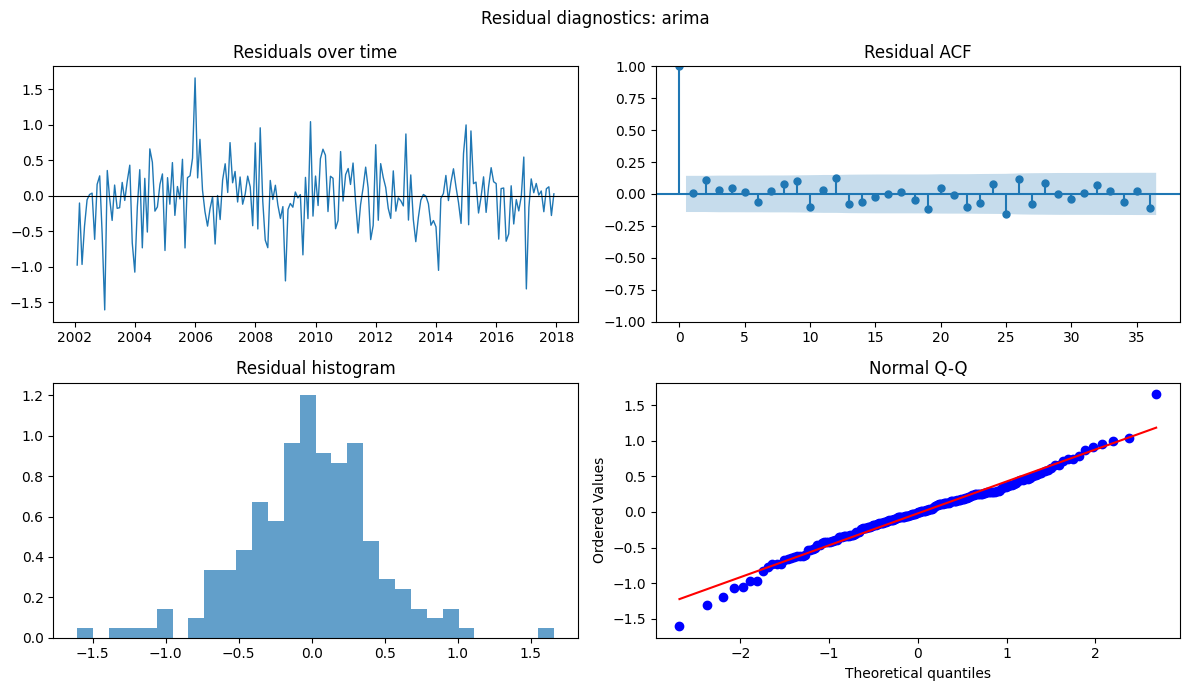

Ljung-Box test, arima (burn-in excluded):
    lb_stat  lb_pvalue
6    3.9491     0.6836
12  13.1282     0.3598
24  24.1993     0.4502


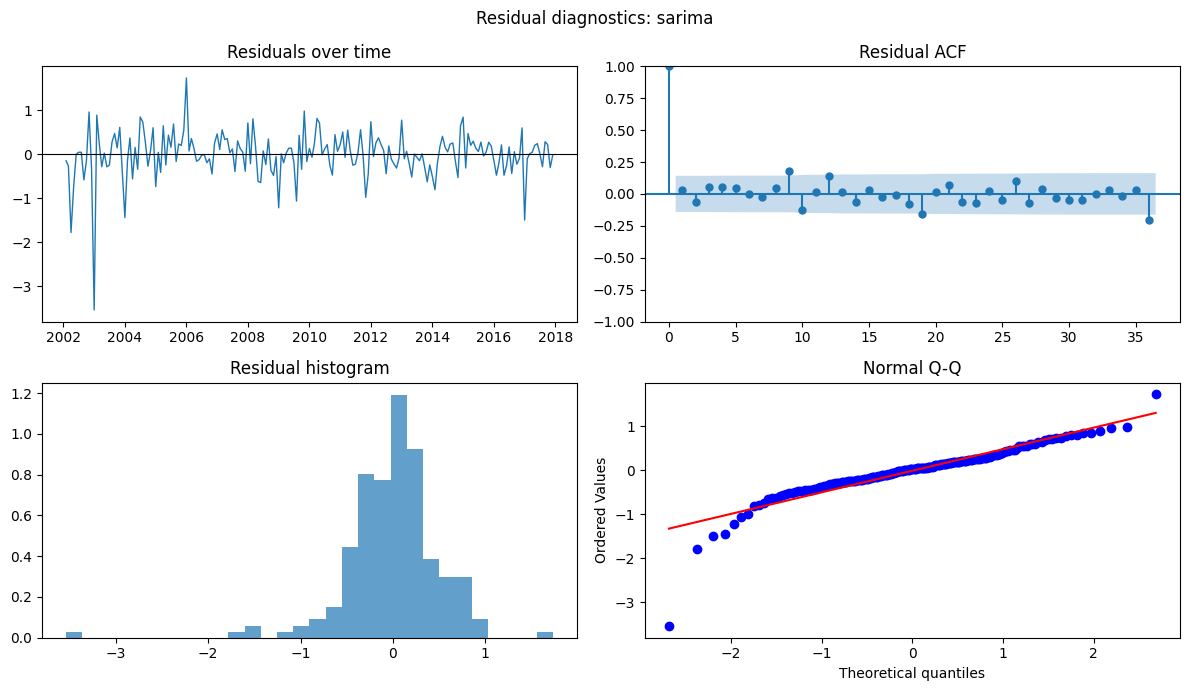

Ljung-Box test, sarima (burn-in excluded):
    lb_stat  lb_pvalue
6    2.4436     0.8747
12  16.5770     0.1662
24  27.7025     0.2728


In [17]:
def residual_diagnostics(res, name):
    resid = res.resid.iloc[BURN_IN:]
    lb = acorr_ljungbox(resid, lags=[6, 12, 24], return_df=True)

    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    axes[0, 0].plot(resid.index, resid, lw=1)
    axes[0, 0].axhline(0, color="k", lw=0.8)
    axes[0, 0].set_title("Residuals over time")
    plot_acf(resid, lags=36, ax=axes[0, 1])
    axes[0, 1].set_title("Residual ACF")
    axes[1, 0].hist(resid, bins=30, density=True, alpha=0.7)
    axes[1, 0].set_title("Residual histogram")
    stats.probplot(resid, dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title("Normal Q-Q")
    fig.suptitle(f"Residual diagnostics: {name}")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"06_residuals_{name}.png", dpi=150)
    plt.show()

    print(f"Ljung-Box test, {name} (burn-in excluded):")
    print(lb.round(4))
    return lb

lb_arima = residual_diagnostics(arima_res, "arima")
lb_sarima = residual_diagnostics(sarima_res, "sarima")

## 9. Save forecasts, intervals and model logs
Notebook 3 reads these files.

In [18]:
forecasts.round(2).to_csv(OUT / "test_forecasts.csv", index_label="date")

pd.concat([
    arima_grid.drop(columns="result").assign(family="ARIMA"),
    sarima_grid.drop(columns="result").assign(family="SARIMA"),
]).to_csv(OUT / "model_selection_log.csv", index=False)

hw_summary.round(4).to_csv(OUT / "holtwinters_summary.csv")

intervals["sarima"].rename(columns={"lower": "sarima_lower", "upper": "sarima_upper"}).round(2) \
    .to_csv(OUT / "sarima_intervals.csv", index_label="date")

(MODEL_DIR / "arima_summary.txt").write_text(str(arima_res.summary()), encoding="utf-8")
(MODEL_DIR / "sarima_summary.txt").write_text(str(sarima_res.summary()), encoding="utf-8")

print("Saved forecasts and logs to", OUT)
forecasts.round(1).head()

Saved forecasts and logs to /Users/arnav/Desktop/Time series Lab/Brazil dengue forcasting project/outputs


,actual,naive,seasonal_naive,arima,sarima,hw_add_log,hw_damped_log,hw_mul_raw
date,,,,,,,,
2018-01-01,1309.0,721.0,1673.0,1049.5,1420.7,1538.5,1259.6,731.1
2018-02-01,1623.0,721.0,1449.0,1368.6,1554.6,2045.0,1400.7,998.6
2018-03-01,2937.0,721.0,1638.0,1486.9,2177.3,3004.2,1789.0,1420.2
2018-04-01,2978.0,721.0,1416.0,1320.5,2522.6,2740.6,1462.9,1053.3
2018-05-01,1791.0,721.0,1158.0,994.2,1764.4,1679.8,823.7,490.1
